# Acceso a los datos: un `Dataset` propio para Oxford Flowers

Un jardín botánico quiere una app que reconozca flores a partir de una foto. En el video *Introduction to Data Pipelines* del curso, tres equipos entrenan la misma red con las mismas fotos y obtienen resultados muy distintos. La diferencia no está en el modelo sino en cómo cada equipo manejó los datos. El curso agrupa los problemas de un pipeline de datos en tres tipos:

- **acceso**: encontrar los archivos y asociar cada imagen con su etiqueta;
- **calidad**: dejar cada imagen con el tamaño, el tipo de dato y la escala que espera el modelo;
- **eficiencia**: cargar los datos por lotes, sin que la carga frene el entrenamiento.

Este notebook trata el acceso. En el módulo 2, `datasets.MNIST` resolvía todo eso por nosotros. **Oxford Flowers 102** llega como llega la mayoría de los datos reales: 8.189 fotos con nombres que no dicen nada (`image_00001.jpg`, `image_00002.jpg`, ...), de tamaños distintos, sin carpetas por clase, y con las etiquetas aparte, en un archivo de MATLAB. Aquí escribimos el `Dataset` que une fotos y etiquetas, y después nos equivocamos a propósito en los dos detalles que advierte el video *Data Access* del curso (las etiquetas parten en 1 y los nombres de archivo también) para ver qué hace cada error y cómo atraparlo antes de entrenar.

- Exploramos los archivos y las etiquetas sin escribir todavía ningún `Dataset`.
- Escribimos un `Dataset` que guarda solo rutas y etiquetas, y abre cada foto recién cuando se la piden.
- Medimos por qué no conviene cargar las 8.189 fotos al principio.
- Reproducimos los errores de las etiquetas y de los nombres, incluida una versión que no da ningún error.
- Escribimos una función que revisa el `Dataset` antes de entrenar y atrapa todos esos errores.

El notebook tarda menos de un minuto en una CPU, sin contar la primera descarga de los datos (345 MB).

**Contenido**

1. Preparación
2. Los archivos
3. Las etiquetas
4. Las fotos vienen agrupadas por clase
5. Un `Dataset` propio
6. Por qué no cargar todo de una vez
7. Etiquetas que parten en 1
8. Nombres que parten en 1
9. Probar el `Dataset` antes de entrenar
10. El mismo patrón, en todas partes
11. Resumen y ejercicios

## 1. Preparación

Usamos `scipy` para leer el archivo de MATLAB y `PIL` (la librería Pillow) para abrir las fotos. `torchvision` la usamos solo para descargar los datos y, al final, para comparar nuestro `Dataset` con el suyo. La descarga deja todo en `modulo-3/data/flowers-102`, una carpeta que comparten los notebooks del módulo. Desde cada notebook es `../data`.

In [1]:
from collections import Counter
import inspect
import os
import time

import numpy as np
import scipy.io
import torch
from torch import nn
from torch.utils.data import Dataset
from torchvision import datasets
from PIL import Image
import matplotlib.pyplot as plt

torch.manual_seed(0)
print("Versión de PyTorch:", torch.__version__)

RAIZ = "../data"       # modulo-3/data


def tamano_legible(n_bytes):
    for unidad in ["B", "KB", "MB", "GB", "TB"]:
        if n_bytes < 1000:
            return f"{n_bytes:.0f} {unidad}"
        n_bytes /= 1000

Versión de PyTorch: 2.11.0+cpu


In [2]:
# La primera vez descarga 345 MB y los descomprime en ../data/flowers-102. Después solo comprueba que estén.
flores_torchvision = datasets.Flowers102(root=RAIZ, split="train", download=True)

CARPETA = os.path.join(RAIZ, "flowers-102")
for nombre in ["102flowers.tgz", "jpg", "imagelabels.mat", "setid.mat"]:
    ruta = os.path.join(CARPETA, nombre)
    if os.path.isdir(ruta):
        print(f"{nombre:16s} carpeta con {len(os.listdir(ruta))} archivos")
    else:
        print(f"{nombre:16s} {tamano_legible(os.path.getsize(ruta))}")

102flowers.tgz   345 MB
jpg              carpeta con 8189 archivos
imagelabels.mat  502 B
setid.mat        15 KB


La descarga deja cuatro cosas en la carpeta: el archivo comprimido (`102flowers.tgz`), la carpeta `jpg` con las fotos ya descomprimidas, `imagelabels.mat` con las etiquetas, que pesa apenas 502 bytes, y `setid.mat` con una división en entrenamiento, validación y prueba. Es lo que describe el [README del conjunto](https://thor.robots.ox.ac.uk/flowers/102/README.txt): las fotos están en `102flowers.tgz` y las etiquetas en `imagelabels.mat`. La división de `setid.mat` la usamos en `02-carga/01_division_y_dataloader`.

## 2. Los archivos

Empezamos por lo más básico: cuántos archivos hay, cómo se llaman y cuánto pesan.

In [3]:
CARPETA_IMAGENES = os.path.join(CARPETA, "jpg")
archivos = sorted(os.listdir(CARPETA_IMAGENES))
bytes_en_disco = sum(os.path.getsize(os.path.join(CARPETA_IMAGENES, nombre)) for nombre in archivos)

print("archivos:", len(archivos))
print("primeros:", archivos[:3])
print("últimos :", archivos[-2:])
print("en disco:", tamano_legible(bytes_en_disco))

archivos: 8189
primeros: ['image_00001.jpg', 'image_00002.jpg', 'image_00003.jpg']
últimos : ['image_08188.jpg', 'image_08189.jpg']
en disco: 347 MB


8.189 fotos, de `image_00001.jpg` a `image_08189.jpg`, que ocupan 347 MB. Dos detalles de los nombres que importan más adelante:

- **Parten en 1, no en 0.** No existe `image_00000.jpg`. Python cuenta desde 0, así que la foto en la posición `idx` de una lista se llama `image_{idx + 1}`.
- **Tienen ceros a la izquierda.** Por eso `sorted` los deja en el orden correcto. Sin los ceros, `sorted` compara letra por letra y el 10 queda antes que el 2:

In [4]:
print(sorted(["image_1.jpg", "image_2.jpg", "image_10.jpg", "image_100.jpg"]))
print(sorted(["image_00001.jpg", "image_00002.jpg", "image_00010.jpg", "image_00100.jpg"]))

['image_1.jpg', 'image_10.jpg', 'image_100.jpg', 'image_2.jpg']
['image_00001.jpg', 'image_00002.jpg', 'image_00010.jpg', 'image_00100.jpg']


Con nombres sin ceros, una lista armada con `sorted(os.listdir(...))` quedaría en otro orden que las etiquetas, y cada foto recibiría la etiqueta de otra. Aquí no pasa, pero conviene mirarlo siempre que el orden de los archivos tenga que calzar con el de las etiquetas.

Ahora los tamaños. `Image.open` no decodifica la foto. Según el [tutorial de Pillow](https://pillow.readthedocs.io/en/stable/handbook/tutorial.html#create-jpeg-thumbnails), al abrir un archivo se lee el encabezado, de donde salen el formato, el modo (RGB, escala de grises, ...) y el tamaño, y el resto del archivo no se procesa hasta más adelante. Así se pueden mirar las 8.189 sin decodificar ninguna:

In [5]:
inicio = time.perf_counter()
tamanos, modos = [], []
for nombre in archivos:
    with Image.open(os.path.join(CARPETA_IMAGENES, nombre)) as imagen:
        tamanos.append(imagen.size)            # (ancho, alto), leído del encabezado
        modos.append(imagen.mode)              # RGB, L (escala de grises), ...
t_encabezados = time.perf_counter() - inicio

anchos = np.array([ancho for ancho, _ in tamanos])
altos = np.array([alto for _, alto in tamanos])
lado_corto = np.minimum(anchos, altos)

print(f"tamaños distintos: {len(set(tamanos))}")
print(f"ancho entre {anchos.min()} y {anchos.max()} píxeles, alto entre {altos.min()} y {altos.max()}")
print(f"lado corto entre {lado_corto.min()} y {lado_corto.max()}; en {np.mean(lado_corto == 500):.1%} de las fotos mide 500")
print(f"horizontales {np.mean(anchos > altos):.1%}   verticales {np.mean(anchos < altos):.1%}   cuadradas {np.mean(anchos == altos):.1%}")
print("los más comunes:", Counter(tamanos).most_common(3))
print("modos:", dict(Counter(modos)))
print(f"leer los {len(archivos)} encabezados tomó {t_encabezados:.1f} s")

tamaños distintos: 856
ancho entre 500 y 1024 píxeles, alto entre 500 y 1168
lado corto entre 500 y 707; en 95.6% de las fotos mide 500
horizontales 75.0%   verticales 24.2%   cuadradas 0.9%
los más comunes: [((667, 500), 1486), ((752, 500), 834), ((666, 500), 350)]
modos: {'RGB': 8189}
leer los 8189 encabezados tomó 8.5 s


Hay más de 800 tamaños distintos. Casi todas las fotos tienen el lado corto de 500 píxeles y el largo varía según el encuadre, y la mayoría son horizontales. Todas vienen en modo RGB, con tres canales. Un modelo necesita entradas del mismo tamaño, así que ese es el primer problema de **calidad**, el tema de `01-calidad/01_transforms_para_fotos`. Por ahora solo los anotamos.

## 3. Las etiquetas

Las etiquetas vienen en `imagelabels.mat`, un archivo de MATLAB. `scipy.io.loadmat` lo lee y, según su [documentación](https://docs.scipy.org/doc/scipy/reference/generated/scipy.io.loadmat.html), devuelve un diccionario con los nombres de las variables como claves y las matrices como valores:

In [6]:
mat = scipy.io.loadmat(os.path.join(CARPETA, "imagelabels.mat"))
print("claves:", list(mat.keys()))

etiquetas_mat = mat["labels"]
print("tipo:", type(etiquetas_mat).__name__, "  forma:", etiquetas_mat.shape, "  dtype:", etiquetas_mat.dtype)

etiquetas_mat = etiquetas_mat[0]            # de una matriz [1, 8189] a un vector [8189]
print("primeras:", etiquetas_mat[:12])
print("mínimo:", etiquetas_mat.min(), "  máximo:", etiquetas_mat.max(), "  clases distintas:", len(np.unique(etiquetas_mat)))

claves: ['__header__', '__version__', '__globals__', 'labels']
tipo: ndarray   forma: (1, 8189)   dtype: uint8
primeras: [77 77 77 77 77 77 77 77 77 77 77 77]
mínimo: 1   máximo: 102   clases distintas: 102


Cuatro cosas que no se ven en el nombre del archivo:

- Las claves `__header__`, `__version__` y `__globals__` las agrega `scipy` con datos del archivo. La única variable es `labels`.
- En MATLAB todo es una matriz, así que una lista de 8.189 números llega como una matriz de una fila, `[1, 8189]`. Con `[0]` nos quedamos con la fila. Otra forma es `loadmat(..., squeeze_me=True)`, que quita las dimensiones de tamaño 1 (ejercicio 2).
- Hay una etiqueta por foto, en el mismo orden que los archivos: la etiqueta `i` es de `image_{i + 1}`.
- Van **de 1 a 102**, como se acostumbra en MATLAB. `CrossEntropyLoss` espera índices de clase en el rango $[0, C)$, de 0 a 101 ([documentación](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)). Hay que restar 1, y la sección 7 muestra qué pasa si no.

El tipo es `uint8`, enteros sin signo de 8 bits. En ese tipo no existen los negativos y las restas dan la vuelta:

In [7]:
clase_1 = etiquetas_mat[etiquetas_mat == 1][:3]       # tres fotos de la clase 1, todavía en uint8
print("etiquetas en el .mat      :", clase_1)
print("uint8, restar 1 una vez   :", clase_1 - 1)
print("uint8, restar 1 dos veces :", clase_1 - 1 - 1, "  máximo de todo el vector:", (etiquetas_mat - 1 - 1).max())
print("int64, restar 1 dos veces :", clase_1.astype(np.int64) - 1 - 1)

etiquetas en el .mat      : [1 1 1]
uint8, restar 1 una vez   : [0 0 0]
uint8, restar 1 dos veces : [255 255 255]   máximo de todo el vector: 255
int64, restar 1 dos veces : [-1 -1 -1]


Restar 1 una vez funciona. Pero si alguien resta 1 dos veces (una al leer el archivo y otra en el `Dataset`, por ejemplo), la etiqueta 1 no queda en −1 sino en 255, sin ningún aviso, y la etiqueta más alta del vector pasa a ser 255. Convertir a `int64` antes de hacer cuentas evita la sorpresa, y además es el tipo que pide la documentación de `CrossEntropyLoss` para los índices de clase.

El archivo trae números, no nombres. `datasets.Flowers102` de torchvision sí trae la lista de nombres, en el orden de las clases 0 a 101:

In [8]:
nombres = flores_torchvision.classes
print(len(nombres), "nombres. Los primeros:", nombres[:4])
print("la etiqueta 77 del .mat, la de image_00001.jpg, es la clase 76:", nombres[77 - 1])

102 nombres. Los primeros: ['pink primrose', 'hard-leaved pocket orchid', 'canterbury bells', 'sweet pea']
la etiqueta 77 del .mat, la de image_00001.jpg, es la clase 76: passion flower


Una mirada a ocho fotos repartidas por el conjunto, con su clase y su tamaño:

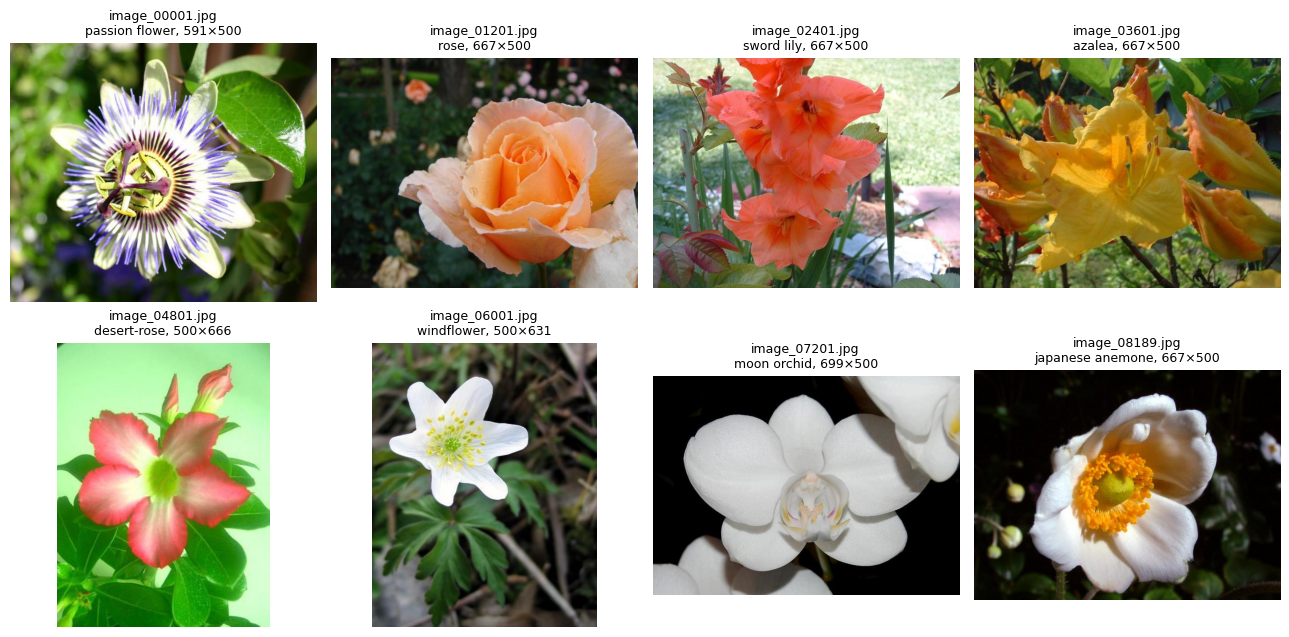

In [9]:
posiciones = [0, 1200, 2400, 3600, 4800, 6000, 7200, 8188]
fig, ejes = plt.subplots(2, 4, figsize=(13, 6.4))
for eje, i in zip(ejes.flat, posiciones):
    with Image.open(os.path.join(CARPETA_IMAGENES, archivos[i])) as imagen:
        eje.imshow(imagen)
    ancho, alto = tamanos[i]
    eje.set_title(f"{archivos[i]}\n{nombres[etiquetas_mat[i] - 1]}, {ancho}×{alto}", fontsize=9)
    eje.axis("off")
plt.tight_layout()
plt.show()

Fotos de cerca, de lejos, con varias flores o una sola, con fondos muy distintos. La [página del conjunto](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/) lo advierte: las imágenes tienen grandes variaciones de escala, de pose y de luz, y hay clases muy parecidas entre sí.

¿Cuántas fotos hay de cada clase?

la que menos: 40 fotos (pink primrose)
la que más  : 258 fotos (petunia)
mediana     : 66 fotos
clases con menos de 50 fotos: 28   con más de 150: 9


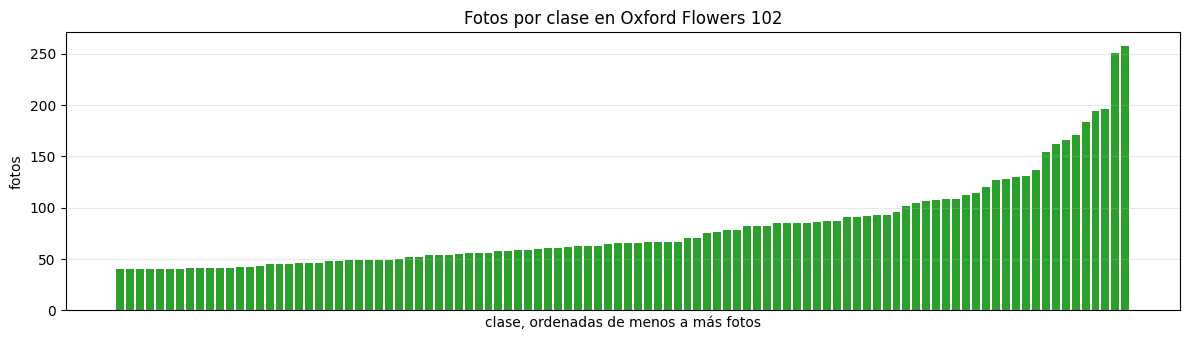

In [10]:
conteo = np.bincount(etiquetas_mat, minlength=103)[1:]          # conteo[k]: fotos de la clase k (0 a 101)
orden = np.argsort(conteo)
print(f"la que menos: {conteo.min()} fotos ({nombres[orden[0]]})")
print(f"la que más  : {conteo.max()} fotos ({nombres[orden[-1]]})")
print(f"mediana     : {np.median(conteo):.0f} fotos")
print(f"clases con menos de 50 fotos: {np.sum(conteo < 50)}   con más de 150: {np.sum(conteo > 150)}")

fig, eje = plt.subplots(figsize=(12, 3.5))
eje.bar(range(102), conteo[orden], color="tab:green")
eje.set_xlabel("clase, ordenadas de menos a más fotos")
eje.set_ylabel("fotos")
eje.set_title("Fotos por clase en Oxford Flowers 102")
eje.set_xticks([])
eje.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Entre 40 y 258 fotos por clase, lo mismo que dice la [página del conjunto](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/). La mitad de las clases tiene 66 fotos o menos, 28 tienen menos de 50 y solo 9 pasan de 150. El conjunto está **desbalanceado**: un modelo verá más de seis veces más fotos de petunias que de prímulas rosadas (*pink primrose*). Lo tomamos en cuenta al dividir los datos, en `02-carga/01_division_y_dataloader`.

Un detalle de historia: según el [README](https://thor.robots.ox.ac.uk/flowers/102/README.txt), el artículo original usó 103 clases; después se juntaron las dos clases de petunias porque eran la misma flor, y la petunia es justo la clase con más fotos. En la sección 4 aparece una pista de esa fusión. El número de clases es una propiedad de la versión de los datos, no algo que se pueda suponer.

## 4. Las fotos vienen agrupadas por clase

Las primeras doce etiquetas eran todas 77. Graficamos la etiqueta de cada archivo contra su número:

cambios de clase: 124   tramos: 125
clases repartidas en más de un tramo: 22
los primeros cinco tramos (etiqueta, fotos): [(77, 251), (73, 194), (88, 152), (89, 183), (81, 166)]
tramos de la petunia (etiqueta 51): [177, 81]
dividiendo por posición 70/15/15: 44 clases sin ninguna foto de entrenamiento, 18 solo en la prueba


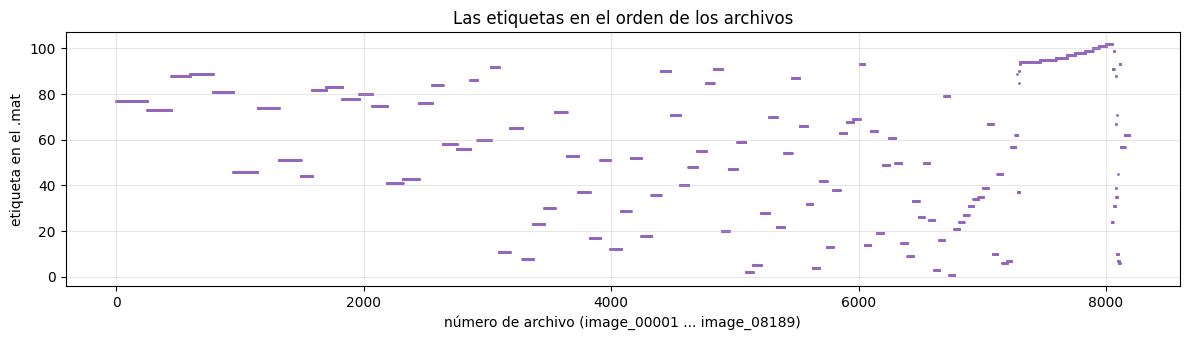

In [11]:
cambios = np.flatnonzero(etiquetas_mat[1:] != etiquetas_mat[:-1]) + 1     # posiciones donde empieza otra clase
tramos = np.split(etiquetas_mat, cambios)
repetidas = sum(1 for veces in Counter(int(tramo[0]) for tramo in tramos).values() if veces > 1)

print("cambios de clase:", len(cambios), "  tramos:", len(tramos))
print("clases repartidas en más de un tramo:", repetidas)
print("los primeros cinco tramos (etiqueta, fotos):", [(int(tramo[0]), len(tramo)) for tramo in tramos[:5]])
etiqueta_petunia = nombres.index("petunia") + 1
print(f"tramos de la petunia (etiqueta {etiqueta_petunia}):", [len(tramo) for tramo in tramos if tramo[0] == etiqueta_petunia])

n_entrenamiento, n_validacion = int(0.70 * len(etiquetas_mat)), int(0.15 * len(etiquetas_mat))
en_entrenamiento = set(etiquetas_mat[:n_entrenamiento].tolist())
en_validacion = set(etiquetas_mat[n_entrenamiento:n_entrenamiento + n_validacion].tolist())
en_prueba = set(etiquetas_mat[n_entrenamiento + n_validacion:].tolist())
print(f"dividiendo por posición 70/15/15: {102 - len(en_entrenamiento)} clases sin ninguna foto de entrenamiento, "
      f"{len(en_prueba - en_entrenamiento - en_validacion)} solo en la prueba")

fig, eje = plt.subplots(figsize=(12, 3.5))
eje.scatter(np.arange(1, len(etiquetas_mat) + 1), etiquetas_mat, s=1, color="tab:purple")
eje.set_xlabel("número de archivo (image_00001 ... image_08189)")
eje.set_ylabel("etiqueta en el .mat")
eje.set_title("Las etiquetas en el orden de los archivos")
eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Los archivos no están mezclados: vienen en bloques de una misma clase. Las primeras 251 fotos tienen la etiqueta 77, las 194 siguientes la etiqueta 73, y así. En total hay 125 tramos y solo 124 cambios de clase en 8.189 fotos. Algunas clases (22) aparecen en más de un tramo, pero el orden sigue lejos de ser aleatorio. Una de ellas es la petunia, en dos tramos separados de 177 y 81 fotos. Calza con dos clases que se juntaron, pero es una suposición nuestra: el README no dice cuántas fotos tenía cada una.

Ni la página ni el README lo mencionan; lo vemos en los datos. Tiene dos consecuencias que se tratan más adelante:

- **Mezclar al entrenar es obligatorio.** Sin mezclar, el modelo vería 251 fotos de una flor, después 194 de otra, y olvidaría cada una al pasar a la siguiente. Es lo que pasó en `04-clasificacion-de-imagenes/02_experimentos_con_mnist` del módulo 2 con MNIST ordenado por dígito.
- **No se puede dividir por posición.** Si el primer 70% fuera el entrenamiento, el 15% siguiente la validación y el resto la prueba, 44 de las 102 clases no tendrían ninguna foto de entrenamiento y 18 aparecerían solo en la prueba. Cómo dividir bien se ve en `02-carga/01_division_y_dataloader`.

Y una tercera, que aparece en la sección 8: un error que corre las etiquetas en una posición solo deja mal las fotos que están en los 124 bordes entre tramos.

## 5. Un `Dataset` propio

Un `Dataset` de PyTorch es un objeto que responde tres preguntas, una por método:

| Método | Pregunta |
|---|---|
| `__init__` | ¿Dónde están los datos y cómo los preparo? |
| `__len__` | ¿Cuántas muestras hay? |
| `__getitem__(idx)` | Si me piden la muestra `idx`, ¿qué entrego? |

La [documentación de `torch.utils.data`](https://docs.pytorch.org/docs/stable/data.html#map-style-datasets) llama a este tipo *map-style*: un objeto que implementa `__getitem__()` y `__len__()` y que va de un índice a una muestra. En el módulo 2 envolvimos un `Dataset` existente (`00-datos/01_transforms_dataset_y_dataloader`, sección 7). Aquí escribimos uno desde cero.

La regla de diseño es la del video *Data Access* del curso: **`__init__` liviano, `__getitem__` perezoso**. El constructor solo guarda dónde está cada foto y su etiqueta, y la foto se abre recién cuando alguien la pide.

In [12]:
class FloresOxford(Dataset):
    """Oxford Flowers 102 a partir de los archivos crudos: jpg/ e imagelabels.mat."""

    def __init__(self, raiz, transform=None):
        carpeta = os.path.join(raiz, "flowers-102")
        self.carpeta_imagenes = os.path.join(carpeta, "jpg")
        etiquetas = scipy.io.loadmat(os.path.join(carpeta, "imagelabels.mat"))["labels"][0]
        self.etiquetas = etiquetas.astype(np.int64) - 1        # 1..102  ->  0..101
        self.transform = transform

    def __len__(self):
        return len(self.etiquetas)

    def ruta(self, idx):
        return os.path.join(self.carpeta_imagenes, f"image_{idx + 1:05d}.jpg")    # los archivos parten en 1

    def __getitem__(self, idx):
        with Image.open(self.ruta(idx)) as imagen:
            imagen = imagen.convert("RGB")        # lee los píxeles y devuelve una copia
        if self.transform is not None:
            imagen = self.transform(imagen)
        return imagen, int(self.etiquetas[idx])


flores = FloresOxford(RAIZ)
print("muestras:", len(flores))

imagen, etiqueta = flores[0]
print(f"flores[0]: {type(imagen).__name__}, {imagen.size}, modo {imagen.mode}   etiqueta {etiqueta} ({nombres[etiqueta]})")
imagen, etiqueta = flores[len(flores) - 1]
print(f"flores[8188]: {imagen.size}   etiqueta {etiqueta} ({nombres[etiqueta]})")

muestras: 8189
flores[0]: Image, (591, 500), modo RGB   etiqueta 76 (passion flower)
flores[8188]: (667, 500)   etiqueta 61 (japanese anemone)


Las dos correcciones que pide el formato de los archivos están cada una en una línea: `- 1` en las etiquetas e `idx + 1` en el nombre. `flores[0]` es `image_00001.jpg`, una pasionaria (*passion flower*), y `flores[8188]` es la última foto, una anémona japonesa, igual que en la grilla de la sección 3.

El método `ruta` no es obligatorio, pero separa "qué archivo corresponde a `idx`" de "cómo se carga". Eso hace el `Dataset` más fácil de probar (sección 9). El argumento `transform` queda listo para el próximo notebook. Por ahora `flores[i]` entrega una imagen de PIL, no un tensor.

**¿Por qué el `with` y el `convert`?** `Image.open` es perezoso: según la [documentación de Pillow](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.open), identifica el archivo, pero el archivo queda abierto y los píxeles no se leen hasta que se procesa la imagen o se llama a `load()`. Lo vemos con `fp`, un atributo interno de Pillow que usamos solo para mirar:

In [13]:
imagen = Image.open(flores.ruta(0))
print("después de open   : tamaño", imagen.size, "  ¿archivo abierto?", imagen.fp is not None)
imagen.load()
print("después de load   : ¿archivo abierto?", imagen.fp is not None)

with Image.open(flores.ruta(0)) as original:
    copia = original.convert("RGB")
print("después del with  : ¿archivo abierto?", original.fp is not None, "  la copia sigue servible:", copia.size, copia.mode)

después de open   : tamaño (591, 500)   ¿archivo abierto? True
después de load   : ¿archivo abierto? False
después del with  : ¿archivo abierto? False   la copia sigue servible: (591, 500) RGB


Después de `open` ya se conoce el tamaño, pero el archivo sigue abierto. `load()` lee los píxeles y, para una imagen de un solo cuadro como un JPEG, cierra el archivo ([*File handling in Pillow*](https://pillow.readthedocs.io/en/stable/reference/open_files.html)). En `__getitem__` usamos `convert("RGB")`, que lee los píxeles y devuelve una copia convertida, dentro de un `with`, que cierra el archivo al salir; es lo que recomienda la misma página. Así cada llamada a `__getitem__` deja el archivo cerrado, aunque se lean miles por época. El `convert("RGB")` sirve además para otra cosa: garantiza tres canales aunque alguna foto venga en escala de grises. En Flowers todas vienen en RGB (lo contamos en la sección 2), pero en `03-robustez/01_pipelines_a_prueba_de_fallas` aparecen archivos que no.

## 6. Por qué no cargar todo de una vez

La alternativa sería decodificar las 8.189 fotos en `__init__` y guardarlas en una lista. Medimos qué costaría. Primero el constructor actual, que no abre ninguna foto:

In [14]:
inicio = time.perf_counter()
flores = FloresOxford(RAIZ)
print(f"crear el Dataset: {(time.perf_counter() - inicio) * 1000:.1f} ms")

bytes_decodificadas = sum(ancho * alto * 3 for ancho, alto in tamanos)       # 3 bytes por píxel (RGB, uint8)
print(f"las 8.189 fotos en disco (JPEG)          : {tamano_legible(bytes_en_disco):>7s}")
print(f"las 8.189 fotos decodificadas (uint8)    : {tamano_legible(bytes_decodificadas):>7s}")
print(f"las 8.189 como tensores float32          : {tamano_legible(bytes_decodificadas * 4):>7s}")
print(f"el JPEG comprime unas {bytes_decodificadas / bytes_en_disco:.0f} veces")

crear el Dataset: 1.3 ms
las 8.189 fotos en disco (JPEG)          :  347 MB
las 8.189 fotos decodificadas (uint8)    :    8 GB
las 8.189 como tensores float32          :   33 GB
el JPEG comprime unas 24 veces


Crear el `Dataset` toma milisegundos: leer un archivo `.mat` de 502 bytes y armar un vector. Las fotos, en cambio, ocupan 347 MB comprimidas en JPEG, pero **8 GB** decodificadas, porque cada píxel pasa a ocupar 3 bytes. Convertidas a tensores `float32`, que es lo que entrega `ToTensor`, serían 33 GB. Los 8 GB ya son toda la memoria de muchos computadores personales, y 33 GB libres no los tiene casi ninguno. MNIST, en el módulo 2, ocupaba 47 MB en memoria; con fotos reales la regla de "cargar solo lo que se necesita" deja de ser una recomendación.

Ahora el tiempo. Decodificamos 100 fotos al azar con `__getitem__`:

In [15]:
generador = np.random.default_rng(0)
muestra = generador.choice(len(flores), size=100, replace=False)

inicio = time.perf_counter()
for i in muestra:
    flores[int(i)]
por_foto = (time.perf_counter() - inicio) / len(muestra)

print(f"decodificar una foto      : {por_foto * 1000:5.1f} ms")
print(f"las 8.189 en __init__     : unos {por_foto * len(flores):4.0f} s antes de poder entrenar")
print(f"un lote de 32, a pedido   : unos {por_foto * 32 * 1000:4.0f} ms")

decodificar una foto      :   5.5 ms
las 8.189 en __init__     : unos   45 s antes de poder entrenar
un lote de 32, a pedido   : unos  174 ms


Unos milisegundos por foto. Cargar todo en `__init__` haría esperar decenas de segundos antes de ver la primera muestra, y esa espera se repetiría cada vez que se crea el `Dataset`. Con la carga perezosa el mismo trabajo se reparte: cada lote de 32 cuesta una fracción de segundo y se hace justo antes de usarlo. Los tiempos exactos dependen del disco y de la CPU, pero la proporción no cambia.

La carga perezosa no hace gratis la decodificación: igual hay que decodificar cada foto en cada época. Lo que cambia es que nunca hay más de un lote en memoria. Cómo esconder ese costo mientras el modelo entrena (`num_workers`) es un tema de eficiencia, en `02-carga/01_division_y_dataloader`.

## 7. Etiquetas que parten en 1

Primer error a propósito: usar las etiquetas del `.mat` tal como vienen, de 1 a 102. Lo escribimos como una subclase que solo cambia esa línea:

In [16]:
class SinRestar(FloresOxford):
    """Error 1: deja las etiquetas como vienen en el .mat, de 1 a 102."""

    def __init__(self, raiz, transform=None):
        super().__init__(raiz, transform)
        self.etiquetas = self.etiquetas + 1


sin_restar = SinRestar(RAIZ)
print("etiquetas entre", sin_restar.etiquetas.min(), "y", sin_restar.etiquetas.max())

etiquetas entre 1 y 102


El `Dataset` se crea sin problemas y `sin_restar[i]` entrega una foto y un número como siempre. El error aparece recién al calcular la pérdida. Simulamos una época: lotes de 32 en orden aleatorio, la salida de un modelo con 102 salidas recién creado (logits al azar) y `CrossEntropyLoss`. Para no decodificar 8.189 fotos tomamos las etiquetas directamente del vector `etiquetas`, que son las mismas que entregaría el `DataLoader`:

In [17]:
criterio = nn.CrossEntropyLoss()
orden_epoca = torch.randperm(len(sin_restar), generator=torch.Generator().manual_seed(0))
lotes = list(orden_epoca.split(32))

primer_error = None
lotes_con_102 = 0
for numero, indices in enumerate(lotes, start=1):
    y = torch.as_tensor(sin_restar.etiquetas[indices.numpy()])
    logits = torch.randn(len(y), 102)
    try:
        criterio(logits, y)
    except IndexError as error:
        lotes_con_102 += 1
        if primer_error is None:
            primer_error = numero
            print(f"lote {numero}: IndexError: {error}")

print(f"\nlotes por época: {len(lotes)}")
print(f"el primer error saltó en el lote {primer_error}; antes, {primer_error - 1} lotes pasaron sin problema")
print(f"lotes que fallan en la época: {lotes_con_102} (hay {np.sum(sin_restar.etiquetas == 102)} fotos con etiqueta 102)")

lote 6: IndexError: Target 102 is out of bounds.

lotes por época: 256
el primer error saltó en el lote 6; antes, 5 lotes pasaron sin problema
lotes que fallan en la época: 43 (hay 48 fotos con etiqueta 102)


`Target 102 is out of bounds`: con 102 salidas, las clases válidas van de 0 a 101 y la 102 no existe. Lo interesante es **cuándo** salta. Solo fallan los lotes que contienen alguna de las 48 fotos de la clase 102: 43 de los 256 lotes de la época. Los cinco primeros pasaron sin problema, y con otra semilla el error saltaría en otro lote. En CPU, por lo menos, el mensaje es claro. El video *Data Access* advierte que este error puede hacer fallar el entrenamiento sin avisar; la siguiente "solución" muestra una forma en que eso pasa.

La reacción típica ante `out of bounds` es agrandar la salida: si la etiqueta 102 no cabe en 102 salidas, se pone una de 103. Ahí el error desaparece. Para ver qué aprende la salida que sobra, entrenamos una capa lineal con 103 salidas sobre entradas al azar y las etiquetas de 1 a 102 (las entradas no importan: solo miramos la salida 0):

In [18]:
torch.manual_seed(0)
x = torch.randn(len(sin_restar), 16)
y = torch.as_tensor(sin_restar.etiquetas)
modelo = nn.Linear(16, 103)
optimizador = torch.optim.Adam(modelo.parameters(), lr=0.05)

with torch.no_grad():
    p0_antes = torch.softmax(modelo(x), dim=1)[:, 0].mean().item()

for paso in range(300):
    optimizador.zero_grad()
    perdida = criterio(modelo(x), y)       # sin error: todas las etiquetas están entre 0 y 102
    perdida.backward()
    optimizador.step()

with torch.no_grad():
    probabilidades = torch.softmax(modelo(x), dim=1)
print("ejemplos con etiqueta 0               :", (y == 0).sum().item())
print(f"probabilidad media de la clase 0      : antes {p0_antes:.4f}   después {probabilidades[:, 0].mean().item():.6f}")
print("veces que el modelo predice la clase 0:", (probabilidades.argmax(dim=1) == 0).sum().item())

ejemplos con etiqueta 0               : 0
probabilidad media de la clase 0      : antes 0.0088   después 0.000143
veces que el modelo predice la clase 0: 0


Ningún ejemplo tiene etiqueta 0, así que el entrenamiento empuja esa salida hacia abajo hasta que su probabilidad es prácticamente cero. El modelo nunca la predice. Es una neurona desperdiciada, pero el daño serio está en otra parte: **todas las respuestas quedan corridas en uno**. El modelo aprende a contestar 77 para una pasionaria, porque esa es la etiqueta del `.mat`. Al traducir la respuesta a un nombre con la lista de torchvision, que va de 0 a 101:

In [19]:
respuesta = int(etiquetas_mat[0])        # lo que aprende a contestar el modelo de 103 salidas para image_00001.jpg
print("lo que es la foto    :", nombres[respuesta - 1])
print("nombres[respuesta]   :", nombres[respuesta])
try:
    nombres[102]
except IndexError as error:
    print("nombres[102]         : IndexError:", error)

lo que es la foto    : passion flower
nombres[respuesta]   : lotus
nombres[102]         : IndexError: list index out of range


La app diría *lotus* para una pasionaria, y le pasaría lo mismo a cada clase: todas las predicciones con el nombre de la flor siguiente en la lista. La exactitud, medida contra las mismas etiquetas corridas, saldría igual que con las etiquetas correctas, porque el error está igual en las etiquetas y en las predicciones: ninguna métrica lo delata. Solo lo delata alguien que mira las fotos con sus nombres, o el `IndexError` del día en que el modelo conteste 102.

La regla: las etiquetas de clase van de 0 a $C - 1$, con $C$ el número de clases. Si los datos vienen de otra forma, se corrigen una sola vez, en el `Dataset`.

## 8. Nombres que parten en 1

Segundo error: armar el nombre del archivo con `idx` en lugar de `idx + 1`.

In [20]:
class NombreSinCorrer(FloresOxford):
    """Error 2: arma el nombre con idx, pero los archivos parten en image_00001."""

    def ruta(self, idx):
        return os.path.join(self.carpeta_imagenes, f"image_{idx:05d}.jpg")


sin_correr = NombreSinCorrer(RAIZ)
imagen, etiqueta = sin_correr[5]
print(f"sin_correr[5] funciona: abre {os.path.basename(sin_correr.ruta(5))}, etiqueta {etiqueta}")

try:
    sin_correr[0]
except FileNotFoundError as error:
    print("sin_correr[0]: FileNotFoundError, no existe", os.path.basename(error.filename))

sin_correr[5] funciona: abre image_00005.jpg, etiqueta 76
sin_correr[0]: FileNotFoundError, no existe image_00000.jpg


`sin_correr[0]` busca `image_00000.jpg`, que no existe. Es el error que describe el video *Data Access*, y por lo menos avisa. Pero mira `sin_correr[5]`: no dio error y abrió `image_00005.jpg`, que es la foto de la posición 4. Con este bug **todas** las muestras desde la 1 entregan la foto anterior a la que corresponde, junto con la etiqueta de su posición. Solo la 0 falla.

¿Qué pasa si alguien "arregla" el `FileNotFoundError` saltándose el archivo que falta? Es una defensa que se usa en serio para tolerar archivos dañados (la vemos en `03-robustez/01_pipelines_a_prueba_de_fallas`):

In [21]:
class SinCorrerSinError(NombreSinCorrer):
    """Error 2, escondido: si el archivo no existe, entrega la muestra siguiente."""

    def __getitem__(self, idx):
        try:
            return super().__getitem__(idx)
        except FileNotFoundError:
            return self[(idx + 1) % len(self)]


escondido = SinCorrerSinError(RAIZ)
imagen_0, etiqueta_0 = escondido[0]
imagen_1, etiqueta_1 = escondido[1]
print("escondido[0] ya no falla. ¿Es la misma muestra que escondido[1]?",
      np.array_equal(np.asarray(imagen_0), np.asarray(imagen_1)) and etiqueta_0 == etiqueta_1)

escondido[0] ya no falla. ¿Es la misma muestra que escondido[1]? True


Ya no hay ningún error. ¿Cuántas muestras quedaron con la etiqueta equivocada? Para cada índice comparamos la etiqueta que entrega con la etiqueta verdadera del archivo que abre. No hace falta decodificar las fotos: basta con saber qué archivo abre cada índice (`ruta`) y qué etiqueta entrega (`etiquetas`):

In [22]:
mal_etiquetadas = []
for i in range(1, len(escondido)):                                  # el 0 entrega la muestra 1
    numero = int(os.path.basename(escondido.ruta(i))[6:11])          # image_00005.jpg -> 5
    if escondido.etiquetas[i] != etiquetas_mat[numero - 1] - 1:
        mal_etiquetadas.append(i)

abiertos = {os.path.basename(escondido.ruta(i)) for i in range(1, len(escondido))}
print(f"muestras con la etiqueta equivocada: {len(mal_etiquetadas)} de {len(escondido)} ({len(mal_etiquetadas) / len(escondido):.2%})")
print("¿son justo los cambios de clase?    :", mal_etiquetadas == cambios.tolist())
print("¿se usa alguna vez image_08189.jpg? :", "image_08189.jpg" in abiertos)

muestras con la etiqueta equivocada: 124 de 8189 (1.51%)
¿son justo los cambios de clase?    : True
¿se usa alguna vez image_08189.jpg? : False


De 8.189 muestras, 124 quedaron mal: exactamente las de los 124 cambios de clase de la sección 4. Dentro de un tramo, la foto anterior es de la misma clase, así que darle la etiqueta de su posición no cambia nada. Solo en los bordes la foto anterior es de otra flor. Además, la última foto no se usa nunca y la primera aparece dos veces. Los tres primeros bordes:

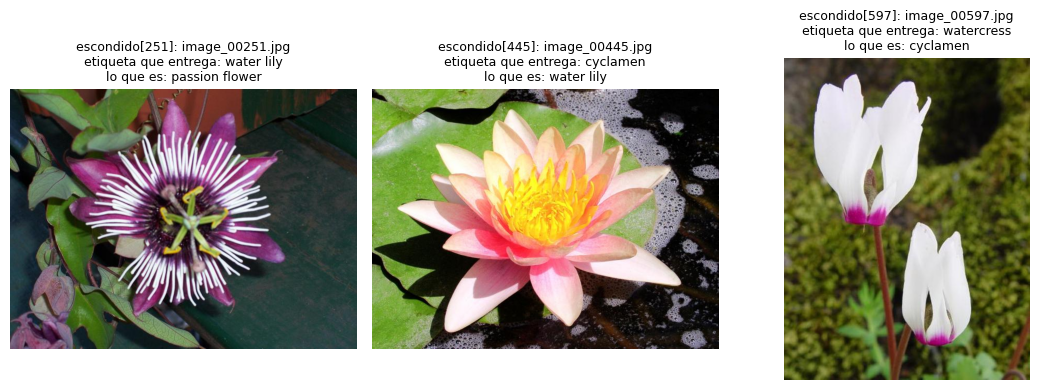

In [23]:
fig, ejes = plt.subplots(1, 3, figsize=(11, 4))
for eje, i in zip(ejes, cambios[:3]):
    imagen, etiqueta = escondido[int(i)]
    numero = int(os.path.basename(escondido.ruta(int(i)))[6:11])
    eje.imshow(imagen)
    eje.set_title(f"escondido[{i}]: {os.path.basename(escondido.ruta(int(i)))}\n"
                  f"etiqueta que entrega: {nombres[etiqueta]}\nlo que es: {nombres[etiquetas_mat[numero - 1] - 1]}", fontsize=9)
    eje.axis("off")
plt.tight_layout()
plt.show()

Cada foto lleva el nombre de la flor del tramo siguiente. Un 1.5% de etiquetas equivocadas es justo el tipo de bug que no se nota: un modelo entrenado con estos datos aprendería casi igual, la exactitud bajaría del orden de un punto, y nadie lo atribuiría a un error en el código. Es nuestro razonamiento, no una medición, pero se apoya en algo que sí medimos: 98.5% de los pares foto-etiqueta están bien.

Que los archivos vengan agrupados por clase es lo que esconde el bug. Con las fotos mezcladas al azar, correr las etiquetas en una posición dejaría mal casi todas las muestras y el modelo no aprendería nada (ejercicio 5).

## 9. Probar el `Dataset` antes de entrenar

El curso recomienda probar el `Dataset` temprano. Los tres errores anteriores pasan inadvertidos con una prueba ingenua, como mirar `dataset[5]`: los tres entregan una imagen y un número razonable. Hace falta una revisión que mire lo que puede salir mal:

- **largo**: tantas muestras como archivos;
- **archivos**: cada índice apunta a un archivo que existe, y los archivos que se usan son exactamente los de la carpeta, sin repetidos ni faltantes;
- **cargan**: las muestras se pueden cargar sin error;
- **tipos**: imagen RGB de PIL y etiqueta entera;
- **rango**: etiquetas entre 0 y 101;
- **clases**: aparecen las 102 clases;
- **referencia**: la etiqueta coincide con la de una implementación independiente.

¿Qué muestras revisar? Las que más fallan: la primera, la última y los dos lados de cada cambio de clase. Como incluyen el comienzo de cada tramo, cubren las 102 clases.

Para la **referencia** usamos `datasets.Flowers102` de torchvision, que es otra implementación del mismo conjunto. Viene dividida según `setid.mat`, así que armamos un diccionario de número de archivo a (división, posición). Que la posición `k` de cada división de torchvision corresponda al archivo número `setid[k]` lo vemos en su código, en la sección 10.

In [24]:
setid = scipy.io.loadmat(os.path.join(CARPETA, "setid.mat"), squeeze_me=True)
divisiones_torchvision = {}
ubicacion = {}                      # número de archivo -> (división, posición en la división de torchvision)
for division, clave in [("train", "trnid"), ("val", "valid"), ("test", "tstid")]:
    divisiones_torchvision[division] = datasets.Flowers102(root=RAIZ, split=division)
    for posicion, numero in enumerate(setid[clave].tolist()):
        ubicacion[numero] = (division, posicion)
print("archivos con referencia:", len(ubicacion))

referencia_cache = {}


def etiqueta_de_referencia(numero):
    if numero not in referencia_cache:
        division, posicion = ubicacion[numero]
        referencia_cache[numero] = divisiones_torchvision[division][posicion][1]
    return referencia_cache[numero]


indices_borde = sorted({0, len(archivos) - 1} | set(cambios.tolist()) | set((cambios - 1).tolist()))
print("muestras a revisar:", len(indices_borde), "  clases que cubren:", len(np.unique(etiquetas_mat[indices_borde])))


def revisar(ds, n_clases=102):
    """Revisa un Dataset de Oxford Flowers. Devuelve {nombre de la revisión: True si pasa}."""
    resultado = {"largo": len(ds) == len(archivos)}

    rutas = [ds.ruta(i) for i in range(len(ds))]
    resultado["archivos"] = (all(os.path.exists(r) for r in rutas) and len(set(rutas)) == len(rutas)
                             and {os.path.basename(r) for r in rutas} == set(archivos))

    cargan = tipos = rango = coincide = True
    clases_vistas = set()
    for i in indices_borde:
        try:
            imagen, etiqueta = ds[i]
        except Exception:
            cargan = False
            continue
        tipos &= isinstance(imagen, Image.Image) and imagen.mode == "RGB" and isinstance(etiqueta, int)
        rango &= 0 <= etiqueta < n_clases
        clases_vistas.add(etiqueta)
        numero = int(os.path.basename(ds.ruta(i))[6:11])
        if numero in ubicacion:
            coincide &= etiqueta == etiqueta_de_referencia(numero)
    resultado.update(cargan=cargan, tipos=tipos, rango=rango,
                     clases=clases_vistas == set(range(n_clases)), referencia=coincide)
    return resultado


inicio = time.perf_counter()
tabla = {clase.__name__: revisar(clase(RAIZ)) for clase in [FloresOxford, SinRestar, NombreSinCorrer, SinCorrerSinError]}
print(f"revisar los cuatro tomó {time.perf_counter() - inicio:.0f} s\n")

revisiones = list(tabla["FloresOxford"])
print(f"{'':20s}" + "".join(f"{r:>12s}" for r in revisiones))
for nombre_clase, resultado in tabla.items():
    print(f"{nombre_clase:20s}" + "".join(f"{'bien' if resultado[r] else 'FALLA':>12s}" for r in revisiones))

archivos con referencia: 8189
muestras a revisar: 246   clases que cubren: 102


revisar los cuatro tomó 11 s

                           largo    archivos      cargan       tipos       rango      clases  referencia
FloresOxford                bien        bien        bien        bien        bien        bien        bien
SinRestar                   bien        bien        bien        bien       FALLA       FALLA       FALLA
NombreSinCorrer             bien       FALLA       FALLA        bien        bien        bien       FALLA
SinCorrerSinError           bien       FALLA        bien        bien        bien        bien       FALLA


El `Dataset` correcto pasa todo y cada error falla en algo:

- `SinRestar` falla en **rango** (aparece la 102), en **clases** (las clases vistas son 1 a 102, no 0 a 101) y en **referencia**.
- `NombreSinCorrer` falla en **archivos** (busca `image_00000.jpg`, que no existe, y nunca usa `image_08189.jpg`; lo segundo solo lo detecta la comparación con los archivos de la carpeta), en **cargan** (el índice 0 da error) y en **referencia**.
- `SinCorrerSinError`, el que no da ningún error al usarlo, falla en **archivos** y en **referencia**. La revisión atrapa justo el bug que el entrenamiento habría escondido.

Toda la revisión tarda unos segundos, nada comparado con un entrenamiento que puede durar horas antes de que alguien sospeche.

¿Por qué revisar los bordes y no una muestra al azar? Con el bug escondido, 124 de las 8.189 muestras están mal. Una revisión de 20 índices al azar tiene que caer en alguna de ellas para notarlo. Calculamos la probabilidad y la comprobamos simulando 10.000 revisiones:

In [25]:
p_mal = len(mal_etiquetadas) / len(escondido)
print(f"probabilidad de detectarlo con 20 índices al azar, calculada: {1 - (1 - p_mal) ** 20:.1%}")

malas = np.zeros(len(escondido), dtype=bool)
malas[mal_etiquetadas] = True
sorteos = np.random.default_rng(0).integers(0, len(escondido), size=(10_000, 20))
print(f"probabilidad de detectarlo con 20 índices al azar, simulada : {malas[sorteos].any(axis=1).mean():.1%}")

probabilidad de detectarlo con 20 índices al azar, calculada: 26.3%
probabilidad de detectarlo con 20 índices al azar, simulada : 26.6%


Una revisión al azar de 20 muestras lo detecta una de cada cuatro veces; tres de cada cuatro diría que todo está bien. Los bugs de desfase viven en los bordes: al principio, al final y donde cambia algo. Las pruebas tienen que ir a buscarlos ahí.

## 10. El mismo patrón, en todas partes

`datasets.Flowers102` de torchvision hace exactamente lo mismo que nuestro `Dataset`. Estas son las líneas de su constructor que tratan las etiquetas y los nombres:

In [26]:
codigo = inspect.getsource(datasets.Flowers102.__init__)
for linea in codigo.splitlines():
    if any(texto in linea for texto in ["set_ids", "image_ids", "image_id_to_label", "image_{"]):
        print(linea.strip())

set_ids = loadmat(self._base_folder / self._file_dict["setid"][0], squeeze_me=True)
image_ids = set_ids[self._splits_map[self._split]].tolist()
image_id_to_label = dict(enumerate((labels["labels"] - 1).tolist(), 1))
for image_id in image_ids:
self._labels.append(image_id_to_label[image_id])
self._image_files.append(self._images_folder / f"image_{image_id:05d}.jpg")


Resta 1 a las etiquetas (`labels["labels"] - 1`) y numera los archivos desde 1 (`enumerate(..., 1)` e `image_{image_id:05d}.jpg`). Las dos correcciones de este notebook son las mismas que hicieron sus autores. La diferencia es el orden: lee de `setid.mat` los números de archivo de la división pedida (`image_ids = set_ids[...]`) y los recorre en ese orden (`for image_id in image_ids`), así que la posición `k` de cada división es el archivo `image_ids[k]`. Es lo que usamos en la revisión de la sección 9.

El patrón de **configuración liviana y carga perezosa** sirve para cualquier tipo de datos. Lo que cambia es cómo se lee una muestra:

- **audio**: `__init__` guarda las rutas de los archivos `.wav` y sus etiquetas; `__getitem__` lee un archivo y lo convierte en un tensor.
- **texto**: `__init__` guarda las rutas o los desplazamientos dentro de un archivo grande; `__getitem__` lee un documento y lo convierte en números.
- **tablas grandes**: `__init__` guarda en qué archivo y fila está cada ejemplo; `__getitem__` lee esa fila.

Y cuando los datos vienen en una carpeta por clase, no hace falta escribir nada: [`torchvision.datasets.ImageFolder`](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.ImageFolder.html) espera la estructura `root/dog/xxx.png`, `root/cat/123.png` y saca la etiqueta del nombre de la carpeta (ejercicio 7). Oxford Flowers no viene así, y por eso escribimos el nuestro.

Lo que todavía no resuelve nuestro `Dataset`: entrega fotos de PIL de tamaños distintos. Un `DataLoader` no puede apilarlas en un lote. Ese es el tema de `01-calidad/01_transforms_para_fotos`.

## 11. Resumen

- Los datos reales rara vez vienen listos: Oxford Flowers trae 8.189 fotos con nombres genéricos, de más de 800 tamaños distintos, y las etiquetas aparte, en un archivo de MATLAB.
- `scipy.io.loadmat` devuelve un diccionario. Las etiquetas llegan como una matriz `[1, 8189]` de tipo `uint8`, de 1 a 102. Conviene pasarlas a `int64` antes de hacer cuentas.
- El conjunto está desbalanceado (de 40 a 258 fotos por clase) y los archivos vienen agrupados por clase: 125 tramos en 8.189 fotos.
- Un `Dataset` propio necesita `__init__`, `__len__` y `__getitem__`. `__init__` guarda solo rutas y etiquetas; `__getitem__` abre la foto cuando se la piden, dentro de un `with` para cerrar el archivo.
- Cargar todo de una vez ocuparía 8 GB como enteros y 33 GB como tensores `float32`, además de decenas de segundos de espera cada vez que se crea el `Dataset`.
- Etiquetas sin restar 1: `CrossEntropyLoss` falla, pero recién en el primer lote que contiene la clase 102. Agrandar la salida a 103 quita el error y corre todos los nombres en uno.
- Nombres sin `idx + 1`: el índice 0 falla. Si se esconde ese error, quedan 124 etiquetas mal, justo en los bordes entre clases, sin ningún aviso.
- Una revisión automática antes de entrenar (largo, archivos, carga, tipos, rango, clases y una referencia independiente) atrapa los tres errores. Hay que revisar los bordes: una muestra al azar de 20 detecta el bug escondido solo una de cada cuatro veces.

## Ejercicios

1. Antes de ejecutar: con `SinRestar` y lotes de 64 en vez de 32, ¿en qué lote esperas el primer error? Calcula la probabilidad de que el primer lote ya contenga alguna de las 48 fotos de la clase 102 y compruébala repitiendo la simulación de la sección 7 con 1.000 semillas.
2. Lee `imagelabels.mat` con `squeeze_me=True`. ¿Qué forma tiene `labels`? Adapta `FloresOxford.__init__` para usarlo.
3. Agrega a `FloresOxford` un argumento `division` (`"train"`, `"val"`, `"test"` o `None` para todo) que use `setid.mat` para quedarse solo con esos archivos. Comprueba que salen 1.020, 1.020 y 6.149 muestras, y que la muestra `k` de cada división coincide en píxeles y etiqueta con la de `datasets.Flowers102`.
4. Agrega a `revisar` una comprobación de que la imagen de cada índice revisado es idéntica, píxel a píxel, a la de torchvision para el mismo archivo. ¿Qué errores de las secciones 7 y 8 atrapa por sí sola?
5. Mezcla al azar el orden de las etiquetas y los archivos (con la misma permutación para los dos, así los pares siguen bien) y repite el bug escondido de la sección 8. ¿Cuántas etiquetas quedan mal ahora? ¿Por qué tantas más?
6. Mide cuánto tarda `__getitem__` si antes de `convert` llamas a `imagen.draft("RGB", (250, 250))`, que le pide al decodificador de JPEG una versión reducida. ¿Qué tamaño tiene la imagen que entrega? ¿Cuándo convendría?
7. Copia las fotos de tres clases a una estructura `flores_por_carpeta/<nombre de la clase>/` y cárgalas con `datasets.ImageFolder`. ¿Qué índice le asigna a cada clase? ¿Coincide con el de `FloresOxford`? Fíjate en el orden de las carpetas.

## Fuentes

Las citas textuales que respaldan cada afirmación, con el lugar exacto donde están. Las páginas se revisaron el 22 de octubre de 2026.

**Del material del curso**

- **Visual Geometry Group, Universidad de Oxford**, [*102 Category Flower Dataset*](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/), la página del conjunto: "We have created a 102 category dataset, consisting of 102 flower categories", "Each class consists of between 40 and 258 images", "The images have large scale, pose and light variations" y "there are categories that have large variations within the category and several very similar categories". El artículo que la página pide citar: M.-E. Nilsback y A. Zisserman, *Automated flower classification over a large number of classes*, Proceedings of the Indian Conference on Computer Vision, Graphics and Image Processing (2008).
- El [README del conjunto](https://thor.robots.ox.ac.uk/flowers/102/README.txt), enlazado desde esa página: "The images are contained in the file 102flowers.tgz and the image labels in imagelabels.mat", "The datasplits used in this paper are specified in setid.mat" (sección *Datasplit*) y "The results in the paper are produced on a 103 category database. The two categories labeled Petunia have since been merged since they are the same."
- Los videos *Introduction to Data Pipelines* (los tres equipos y los tres tipos de problemas) y *Data Access* (etiquetas de 1 a 102, el desfase de los nombres, la carga perezosa y probar el `Dataset` temprano) del módulo 3 del curso.

**Documentación**

- PyTorch, [`torch.utils.data`](https://docs.pytorch.org/docs/stable/data.html), sección *Map-style datasets*: "A map-style dataset is one that implements the `__getitem__()` and `__len__()` protocols". Clase `torch.utils.data.Dataset`: "An abstract class representing a Dataset", y las subclases "should overwrite `__getitem__()`, supporting fetching a data sample for a given key" y "could also optionally overwrite `__len__()`".
- PyTorch, [`torch.nn.CrossEntropyLoss`](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html): el objetivo contiene "Class indices in the range [0, C) where C is the number of classes" y, en la sección *Shape*, "The target data type is required to be long when using class indices".
- SciPy, [`scipy.io.loadmat`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.io.loadmat.html): "Load MATLAB file"; devuelve `mat_dict`, un "dictionary with variable names as keys, and loaded matrices as values"; y `squeeze_me`: "Whether to squeeze unit matrix dimensions or not".
- Pillow, [`PIL.Image.open`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.open): "This is a lazy operation; this function identifies the file, but the file remains open and the actual image data is not read from the file until you try to process the data (or call the load() method)". `Image.convert`: "Returns a converted copy of this image".
- Pillow, [tutorial, sección *Create JPEG thumbnails*](https://pillow.readthedocs.io/en/stable/handbook/tutorial.html#create-jpeg-thumbnails): "It is important to note that the library doesn't decode or load the raster data unless it really has to. When you open a file, the file header is read to determine the file format and extract things like mode, size, and other properties required to decode the file, but the rest of the file is not processed until later."
- Pillow, [*File handling in Pillow*](https://pillow.readthedocs.io/en/stable/reference/open_files.html): "So if the image is a single-frame image, the file will be closed in this method after the frame is read" (sobre `load()`), "The Pillow context manager will also close the file, but will not destroy the core image object" y, en *Proposed file handling*, "Users of the library should use a context manager or call `Image.Image.close()`".
- torchvision, [`datasets.Flowers102`](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.Flowers102.html): "Oxford 102 Flower is an image classification dataset consisting of 102 flower categories", "Each class consists of between 40 and 258 images" y "This class needs scipy to load target files from .mat format". Su [código fuente](https://github.com/pytorch/vision/blob/main/torchvision/datasets/flowers102.py), en `__init__`: `image_id_to_label = dict(enumerate((labels["labels"] - 1).tolist(), 1))` y `f"image_{image_id:05d}.jpg"` (el notebook imprime esas líneas desde la versión instalada).
- torchvision, [`datasets.ImageFolder`](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.ImageFolder.html): "A generic data loader where the images are arranged in this way by default", seguido del ejemplo `root/dog/xxx.png`, `root/cat/123.png`.

**Lo que no viene de una fuente** son los números de este notebook (tamaños, memoria, tiempos, tramos, lotes, probabilidades): todos salen de las celdas de código. Que los archivos vengan agrupados por clase no lo dice ninguna de las fuentes; lo vemos en los datos. También son nuestros los errores sembrados de las secciones 7 y 8, la revisión de la sección 9 y el razonamiento de que el bug escondido casi no se notaría en la exactitud.